In [1]:
import os
import json
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, wilcoxon
from Bio.PDB.MMCIFParser import MMCIFParser
from Bio.PDB import NeighborSearch
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# predicted aligned error (PAE), TF-TF and TF-DNA, high vs low. lower PAE = more confident relative placement
#   mean PAE: full token-pair block from *_confidences.json, both directions averaged (PAE is not symmetric)
#   min PAE: AF3's chain_pair_pae_min from *_summary_confidences.json
# TF1/TF2 averaged for DNA metrics (TF1/TF2 is not a fixed structural role, see notebooks 1/2)
dt = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv", dtype={"motif_combination": str})
manifest = dt[["motif_combination", "background_idx", "class", "TF1", "TF2"]].rename(columns={"motif_combination": "combo"})
manifest["group"] = manifest["TF1"] + "_" + manifest["TF2"] + "_" + manifest["combo"]
manifest["name"] = manifest["group"] + "_" + manifest["class"] + "_bg" + manifest["background_idx"].astype(str)
manifest["conf_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_confidences.json"
manifest["summary_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_summary_confidences.json"
manifest["model_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_model.cif"
manifest["exists"] = manifest["conf_path"].apply(os.path.exists) & manifest["summary_path"].apply(os.path.exists)
manifest["exists"].value_counts()

exists
True    6400
Name: count, dtype: int64

In [3]:
def yy_mean_pae(pae, mask1, mask2):
    """Mean PAE between two token sets, both directions averaged."""
    return 0.5 * (pae[np.ix_(mask1, mask2)].mean() + pae[np.ix_(mask2, mask1)].mean())

def yy_min_pae(pae_min, i, j):
    return 0.5 * (pae_min[i][j] + pae_min[j][i])

In [4]:
# resume from the checkpoint
checkpoint = "../results/cache/pae_checkpoint.csv"
records = pd.read_csv(checkpoint).to_dict("records") if os.path.exists(checkpoint) else []
todo = manifest[manifest["exists"] & ~manifest["name"].isin({r["name"] for r in records})]
print(f"{len(records)} done, {len(todo)} to do")

for i, (_, row) in enumerate(todo.iterrows()):
    d = json.load(open(row["conf_path"]))
    tci = np.array(d["token_chain_ids"])
    pae = np.array(d["pae"])
    A, B, DNA = tci == "A", tci == "B", np.isin(tci, ["C", "D"])
    pae_min = json.load(open(row["summary_path"]))["chain_pair_pae_min"]  # chain order A, B, C, D
    tf1_dna_min = min(yy_min_pae(pae_min, 0, 2), yy_min_pae(pae_min, 0, 3))
    tf2_dna_min = min(yy_min_pae(pae_min, 1, 2), yy_min_pae(pae_min, 1, 3))
    records.append({
        "name": row["name"], "group": row["group"], "combo": row["combo"],
        "background_idx": row["background_idx"], "class": row["class"],
        "TF1": row["TF1"], "TF2": row["TF2"], "pair": row["TF1"] + "-" + row["TF2"],
        "PP_pae_mean": yy_mean_pae(pae, A, B),
        "DNA_pae_mean": 0.5 * (yy_mean_pae(pae, A, DNA) + yy_mean_pae(pae, B, DNA)),
        "PP_pae_min": yy_min_pae(pae_min, 0, 1),
        "DNA_pae_min": 0.5 * (tf1_dna_min + tf2_dna_min),
    })
    if (i + 1) % 500 == 0 or i + 1 == len(todo):
        pd.DataFrame(records).to_csv(checkpoint, index=False)

6400 done, 0 to do


In [5]:
# PP_pae_mean averages the whole A x B block, including residues nowhere near each other.
# restrict to residues actually in contact (heavy atoms <= 4.5 A, as in notebook 2)
parser = MMCIFParser(QUIET=True)

def yy_iface_pae(conf_path, model_path):
    """Mean PAE over (interface residue of A) x (interface residue of B), plus n interface residues."""
    atoms = list(parser.get_structure("x", model_path)[0].get_atoms())
    iface = {"A": set(), "B": set()}
    for a1, a2 in NeighborSearch(atoms).search_all(4.5, level="A"):
        c1, c2 = a1.get_parent().get_parent().id, a2.get_parent().get_parent().id
        if {c1, c2} == {"A", "B"}:
            iface[c1].add(a1.get_parent().id[1])
            iface[c2].add(a2.get_parent().id[1])
    if not iface["A"] or not iface["B"]:
        return np.nan, len(iface["A"]), len(iface["B"])
    d = json.load(open(conf_path))
    tci, tri = np.array(d["token_chain_ids"]), np.array(d["token_res_ids"])
    maskA = (tci == "A") & np.isin(tri, list(iface["A"]))
    maskB = (tci == "B") & np.isin(tri, list(iface["B"]))
    return yy_mean_pae(np.array(d["pae"]), maskA, maskB), len(iface["A"]), len(iface["B"])

In [6]:
# ~1.5h for all models, resume from the checkpoint
checkpoint_iface = "../results/cache/ppi_interface_pae_checkpoint.csv"
iface_records = pd.read_csv(checkpoint_iface).to_dict("records") if os.path.exists(checkpoint_iface) else []
todo = manifest[manifest["exists"] & ~manifest["name"].isin({r["name"] for r in iface_records})]
print(f"{len(iface_records)} done, {len(todo)} to do")

for i, (_, row) in enumerate(todo.iterrows()):
    pae_mean, n_a, n_b = yy_iface_pae(row["conf_path"], row["model_path"])
    iface_records.append({"name": row["name"], "PPI_iface_pae_mean": pae_mean, "n_iface_res_A": n_a, "n_iface_res_B": n_b})
    if (i + 1) % 500 == 0 or i + 1 == len(todo):
        pd.DataFrame(iface_records).to_csv(checkpoint_iface, index=False)

6400 done, 0 to do


In [7]:
results = pd.DataFrame(records).merge(pd.DataFrame(iface_records), on="name", how="left")
results["class"] = pd.Categorical(results["class"], categories=["high", "low"], ordered=True)
results.to_csv("../results/tables/pae_high_vs_low.csv", index=False)
results.head()

,name,group,combo,background_idx,class,TF1,TF2,pair,PP_pae_mean,DNA_pae_mean,PP_pae_min,DNA_pae_min,PPI_iface_pae_mean,n_iface_res_A,n_iface_res_B
0,BCL11B_ETS1_14_64_high_bg0,BCL11B_ETS1_14_64,14_64,0,high,BCL11B,ETS1,BCL11B-ETS1,29.605131,24.708719,2.570,2.5900,26.785828,101,113
1,BCL11B_GABPA_14_64_high_bg0,BCL11B_GABPA_14_64,14_64,0,high,BCL11B,GABPA,BCL11B-GABPA,29.000971,23.349581,3.080,2.3575,20.710896,73,76
2,BCL11B_IKZF1_14_64_high_bg0,BCL11B_IKZF1_14_64,14_64,0,high,BCL11B,IKZF1,BCL11B-IKZF1,30.214751,25.524267,4.580,1.8000,24.666875,42,40
3,RUNX1_ETS1_14_64_high_bg0,RUNX1_ETS1_14_64,14_64,0,high,RUNX1,ETS1,RUNX1-ETS1,27.887795,21.386610,2.025,1.0700,17.631213,29,29
4,RUNX1_GABPA_14_64_high_bg0,RUNX1_GABPA_14_64,14_64,0,high,RUNX1,GABPA,RUNX1-GABPA,27.934015,21.647748,2.090,1.0725,17.936915,37,41


In [8]:
# each background appears in both classes (motif swapped), so also test paired by group + background_idx
for col in ["PP_pae_mean", "PP_pae_min", "PPI_iface_pae_mean", "DNA_pae_mean", "DNA_pae_min"]:
    high = results[results["class"] == "high"][col].dropna()
    low = results[results["class"] == "low"][col].dropna()
    paired = results.pivot_table(index=["group", "background_idx"], columns="class", values=col, observed=True).dropna()
    stat, p_value = mannwhitneyu(high, low, alternative="two-sided")
    w_stat, w_p = wilcoxon(paired["high"], paired["low"], alternative="two-sided")
    print(f"{col}: mean high = {high.mean():.3f}, mean low = {low.mean():.3f}, Mann-Whitney p = {p_value:.2e}, "
          f"paired diff = {(paired['high'] - paired['low']).mean():+.3f}, paired Wilcoxon p = {w_p:.2e} (n = {len(paired)})")

PP_pae_mean: mean high = 29.046, mean low = 29.028, Mann-Whitney p = 4.84e-01, paired diff = +0.018, paired Wilcoxon p = 2.06e-05 (n = 3200)
PP_pae_min: mean high = 7.582, mean low = 7.066, Mann-Whitney p = 4.99e-01, paired diff = +0.516, paired Wilcoxon p = 1.46e-05 (n = 3200)
PPI_iface_pae_mean: mean high = 20.331, mean low = 20.682, Mann-Whitney p = 2.36e-01, paired diff = -0.408, paired Wilcoxon p = 1.31e-02 (n = 3050)
DNA_pae_mean: mean high = 23.985, mean low = 23.930, Mann-Whitney p = 4.60e-01, paired diff = +0.054, paired Wilcoxon p = 6.54e-01 (n = 3200)
DNA_pae_min: mean high = 4.983, mean low = 4.868, Mann-Whitney p = 1.02e-02, paired diff = +0.115, paired Wilcoxon p = 6.08e-01 (n = 3200)


In [9]:
palette = {"high": "#2b8cbe", "low": "#e34a33"}

def yy_boxstrip(df, y, ax):
    sns.boxplot(data=df, x="class", y=y, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=df, x="class", y=y, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.3, ax=ax)

def yy_group_bar(df, y, ax, ascending=False):
    """Per TF1-TF2-combo group mean +/- SD over backgrounds, high vs low."""
    grp = df.groupby(["group", "class"], observed=True)[y].agg(["mean", "std"]).reset_index()
    groups = df.groupby("group")[y].mean().sort_values(ascending=ascending).index
    x = np.arange(len(groups))
    for j, cls in enumerate(["high", "low"]):
        sub = grp[grp["class"] == cls].set_index("group").reindex(groups)
        ax.bar(x + (j - 0.5) * 0.4, sub["mean"], 0.4, yerr=sub["std"], color=palette[cls], label=cls,
               capsize=2, error_kw={"lw": 0.8})
    labels = df.drop_duplicates("group").set_index("group").loc[groups]
    ax.set_xticks(x)
    ax.set_xticklabels(labels["pair"] + "\n(" + labels["combo"] + ")", rotation=90, fontsize=7)
    ax.legend(title="class")

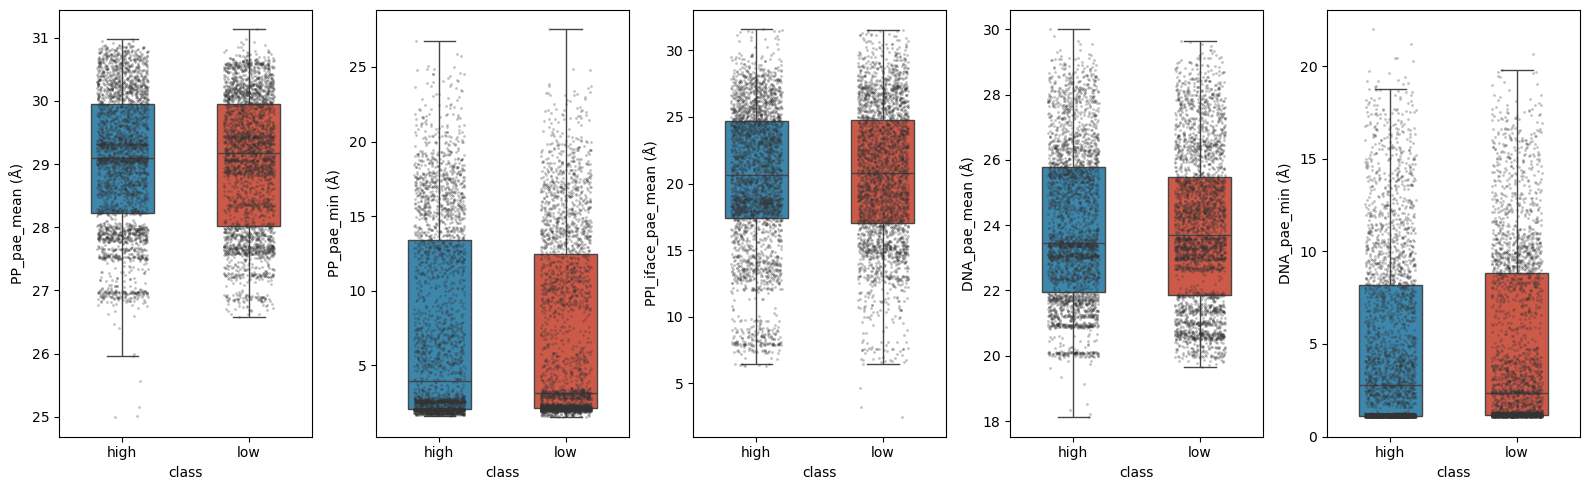

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for ax, col in zip(axes, ["PP_pae_mean", "PP_pae_min", "PPI_iface_pae_mean", "DNA_pae_mean", "DNA_pae_min"]):
    yy_boxstrip(results, col, ax)
    ax.set_ylabel(f"{col} (Å)")
plt.tight_layout()
plt.savefig("../results/figures/pae_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

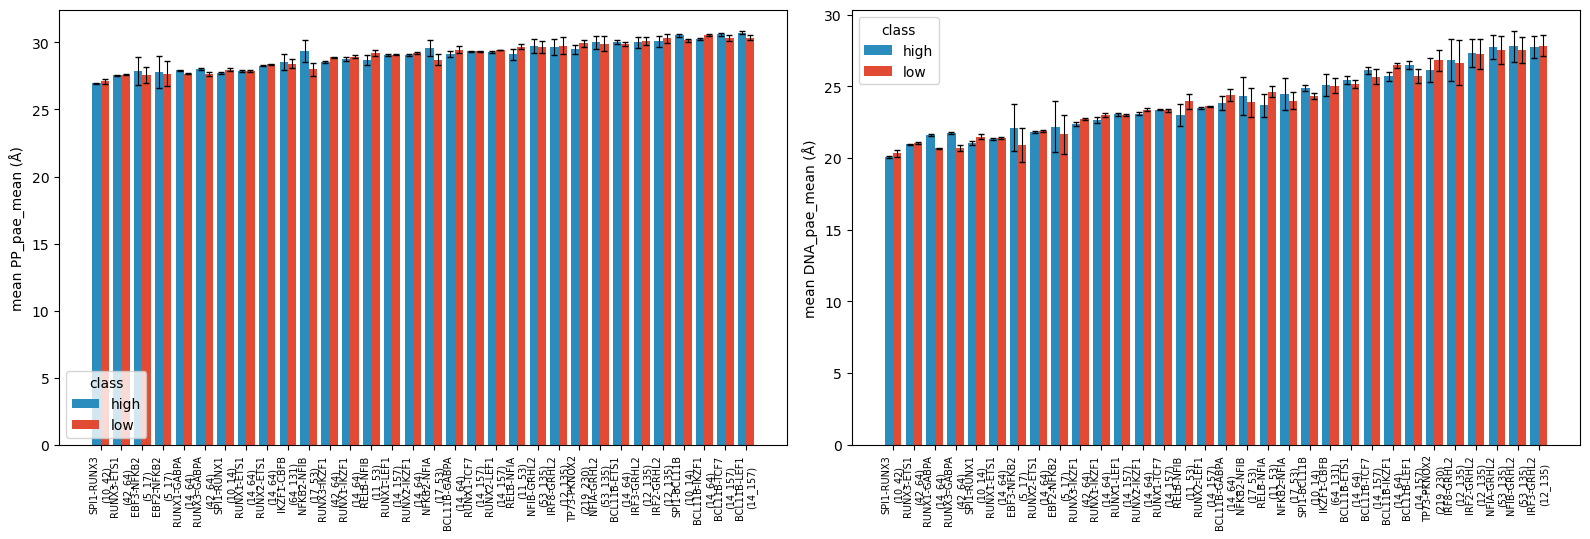

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col in zip(axes, ["PP_pae_mean", "DNA_pae_mean"]):
    yy_group_bar(results, col, ax, ascending=True)
    ax.set_ylabel(f"mean {col} (Å)")
plt.tight_layout()
plt.savefig("../results/figures/pae_per_group_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [12]:
# models with no A-B contact at all have NaN interface PAE - is that failure mode class-dependent?
has_contact = results["PPI_iface_pae_mean"].notna().rename("has_ppi_contact")
contingency = pd.crosstab(results["class"], has_contact)
chi2, p_chi2, dof, expected = stats.chi2_contingency(contingency)
print(f"chi2 = {chi2:.3f}, dof = {dof}, p = {p_chi2:.3g}")
contingency

chi2 = 0.058, dof = 1, p = 0.81


has_ppi_contact,False,True
class,,
high,78,3122
low,82,3118
